In [ ]:
## Inventory Forecast Accuracy Engine

## Objectives

## 1. Calculate forecast accuracy
## 2. Measure forecast bias
## 3. Identify problem items
## 4. Prioritize inventory actions
## 5. Improve replenishment decisions


In [5]:
## Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [6]:
## Create Sample Data

forecast_df = pd.DataFrame({

    "Item": [
        "Item A",
        "Item B",
        "Item C",
        "Item D",
        "Item E"
    ],

    "Forecast": [
        1000,
        850,
        1500,
        1200,
        700
    ],

    "Actual": [
        900,
        1000,
        1600,
        1100,
        600
    ]

})

display(forecast_df)

,Item,Forecast,Actual
0,Item A,1000,900
1,Item B,850,1000
2,Item C,1500,1600
3,Item D,1200,1100
4,Item E,700,600


In [7]:
## Forecast Error

forecast_df["Error"] = (
    forecast_df["Forecast"]
    - forecast_df["Actual"]
)

display(forecast_df)


,Item,Forecast,Actual,Error
0,Item A,1000,900,100
1,Item B,850,1000,-150
2,Item C,1500,1600,-100
3,Item D,1200,1100,100
4,Item E,700,600,100


In [8]:
## Absolute Error

forecast_df["Absolute_Error"] = (
    abs(forecast_df["Error"])
)

display(forecast_df)

,Item,Forecast,Actual,Error,Absolute_Error
0,Item A,1000,900,100,100
1,Item B,850,1000,-150,150
2,Item C,1500,1600,-100,100
3,Item D,1200,1100,100,100
4,Item E,700,600,100,100


In [9]:
## Percent Error

forecast_df["Percent_Error"] = (
    forecast_df["Absolute_Error"]
    / forecast_df["Actual"]
) * 100

display(forecast_df)

,Item,Forecast,Actual,Error,Absolute_Error,Percent_Error
0,Item A,1000,900,100,100,11.111111
1,Item B,850,1000,-150,150,15.000000
2,Item C,1500,1600,-100,100,6.250000
3,Item D,1200,1100,100,100,9.090909
4,Item E,700,600,100,100,16.666667


In [10]:
## Forecast Accuracy %

forecast_df["Forecast_Accuracy"] = (
    100 - forecast_df["Percent_Error"]
)

display(forecast_df)

,Item,Forecast,Actual,Error,Absolute_Error,Percent_Error,Forecast_Accuracy
0,Item A,1000,900,100,100,11.111111,88.888889
1,Item B,850,1000,-150,150,15.000000,85.000000
2,Item C,1500,1600,-100,100,6.250000,93.750000
3,Item D,1200,1100,100,100,9.090909,90.909091
4,Item E,700,600,100,100,16.666667,83.333333


In [11]:
## Calculate Overall Accuracy

overall_accuracy = (
    forecast_df["Forecast_Accuracy"]
    .mean()
)

print(
    f"Overall Forecast Accuracy: "
    f"{overall_accuracy:.2f}%"
)

Overall Forecast Accuracy: 88.38%


In [12]:
## Bias Analysis

forecast_df["Bias"] = np.where(

    forecast_df["Error"] > 0,

    "Over Forecast",

    "Under Forecast"

)

display(forecast_df)

,Item,Forecast,Actual,Error,Absolute_Error,Percent_Error,Forecast_Accuracy,Bias
0,Item A,1000,900,100,100,11.111111,88.888889,Over Forecast
1,Item B,850,1000,-150,150,15.000000,85.000000,Under Forecast
2,Item C,1500,1600,-100,100,6.250000,93.750000,Under Forecast
3,Item D,1200,1100,100,100,9.090909,90.909091,Over Forecast
4,Item E,700,600,100,100,16.666667,83.333333,Over Forecast


In [13]:
## Identify Highest Error Item

largest_error = forecast_df.loc[
    forecast_df["Absolute_Error"].idxmax()
]

largest_error

Item                         Item B
Forecast                        850
Actual                         1000
Error                          -150
Absolute_Error                  150
Percent_Error                  15.0
Forecast_Accuracy              85.0
Bias                 Under Forecast
Name: 1, dtype: object

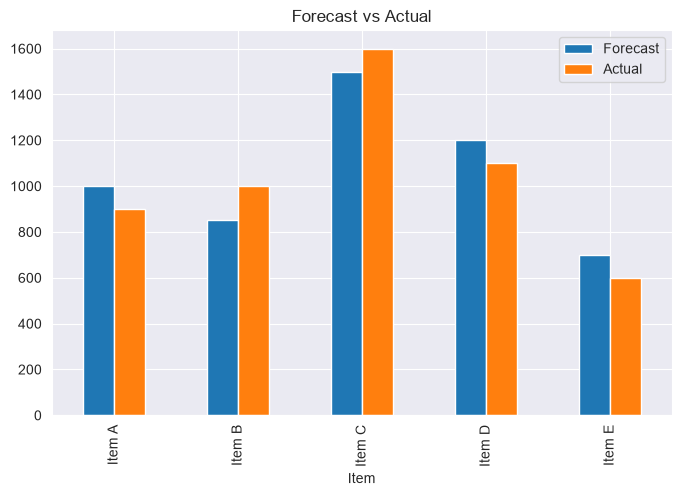

In [14]:
## Forecast vs Actual Chart

forecast_df.plot(

    x="Item",

    y=["Forecast", "Actual"],

    kind="bar",

    figsize=(8,5)

)

plt.title("Forecast vs Actual")

plt.show()

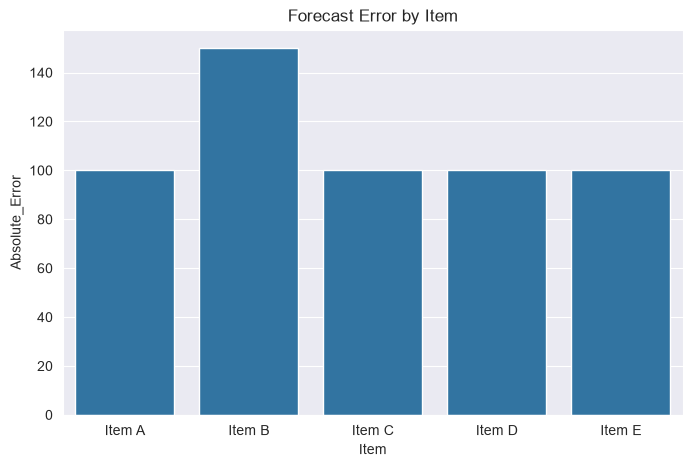

In [15]:
## Error Distribution

plt.figure(figsize=(8,5))

sns.barplot(
    data=forecast_df,
    x="Item",
    y="Absolute_Error"
)

plt.title("Forecast Error by Item")

plt.show()

In [16]:
## Risk Classification

forecast_df["Risk"] = np.where(

    forecast_df["Percent_Error"] > 15,

    "High Risk",

    "Acceptable"

)

display(forecast_df)

,Item,Forecast,Actual,Error,Absolute_Error,Percent_Error,Forecast_Accuracy,Bias,Risk
0,Item A,1000,900,100,100,11.111111,88.888889,Over Forecast,Acceptable
1,Item B,850,1000,-150,150,15.000000,85.000000,Under Forecast,Acceptable
2,Item C,1500,1600,-100,100,6.250000,93.750000,Under Forecast,Acceptable
3,Item D,1200,1100,100,100,9.090909,90.909091,Over Forecast,Acceptable
4,Item E,700,600,100,100,16.666667,83.333333,Over Forecast,High Risk


In [17]:
## Executive Summary Metrics

print("EXECUTIVE METRICS")

print()

print(
    f"Average Accuracy: "
    f"{forecast_df['Forecast_Accuracy'].mean():.1f}%"
)

print(
    f"Total Forecast Units: "
    f"{forecast_df['Forecast'].sum():,.0f}"
)

print(
    f"Total Actual Units: "
    f"{forecast_df['Actual'].sum():,.0f}"
)

EXECUTIVE METRICS

Average Accuracy: 88.4%
Total Forecast Units: 5,250
Total Actual Units: 5,200


In [18]:
## Action Recommendations

recommendations = [

    "Review high-error items",

    "Reduce forecast bias",

    "Improve demand signals",

    "Optimize replenishment settings",

    "Monitor accuracy weekly"

]

for r in recommendations:
    print("-", r)

- Review high-error items
- Reduce forecast bias
- Improve demand signals
- Optimize replenishment settings
- Monitor accuracy weekly


In [19]:
## Forecast Scorecard

scorecard = forecast_df[[

    "Item",
    "Forecast",
    "Actual",
    "Error",
    "Percent_Error",
    "Forecast_Accuracy",
    "Bias",
    "Risk"

]]

display(scorecard)

,Item,Forecast,Actual,Error,Percent_Error,Forecast_Accuracy,Bias,Risk
0,Item A,1000,900,100,11.111111,88.888889,Over Forecast,Acceptable
1,Item B,850,1000,-150,15.000000,85.000000,Under Forecast,Acceptable
2,Item C,1500,1600,-100,6.250000,93.750000,Under Forecast,Acceptable
3,Item D,1200,1100,100,9.090909,90.909091,Over Forecast,Acceptable
4,Item E,700,600,100,16.666667,83.333333,Over Forecast,High Risk


In [21]:
## Interview Takeaways

print("""

KEY TAKEAWAYS

1. Forecast accuracy drives inventory performance

2. Forecast bias creates excess inventory
   or stockouts

3. Error tracking improves replenishment

4. High-risk items need intervention

5. Better forecasts improve working capital

""")



KEY TAKEAWAYS

1. Forecast accuracy drives inventory performance

2. Forecast bias creates excess inventory
   or stockouts

3. Error tracking improves replenishment

4. High-risk items need intervention

5. Better forecasts improve working capital


